**Data sources and limitations**
- Match results: Football-Data’s EPL 2023/24 match file.
- Payroll: FBref’s 2023/24 squad wages table, supplied by Capology; annual GBP amounts used.
- Interpretation: Reported player payroll figures are estimates, not audited total club expenditure.
- Performance scope: Wins and points cover Premier League matches. Player payroll also supports participation in other competitions.
- Points: PointsEarned represents points earned from match results before disciplinary deductions.
- Model scope: One season, 20 clubs; benchmark results are descriptive and were evaluated on the same data used to fit the model.
- FBref defines # Pl as the number of players under contract. This should not be interpreted as the Premier League playing squad size.
- FBref defines % Estimated as the percentage of contracts estimated. This is not a payroll error margin or the proportion of payroll expenditure estimated.
- The glossary does not specify how youth players, loans or mid-season transfers are handled. We therefore use the published squad totals without claiming to have verified those coverage rules.
- Even contracts classified as verified should not be treated as guaranteed exact amounts.

Six of ten lower-payroll clubs exceeded the wins benchmark—the same 60% rate as higher-payroll clubs. Wolves and Bournemouth led the lower-payroll group.

In [1]:
import pandas as pd
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

matches = pd.read_csv(filename)

print("Rows and columns:", matches.shape)
display(matches.head())
print(matches.columns.tolist())

Saving E0.csv to E0.csv
Rows and columns: (380, 106)


,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,...,AvgC<2.5,AHCh,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA
0,E0,11/08/2023,20:00,Burnley,Man City,0,3,A,0,2,...,2.28,1.50,1.95,1.98,1.95,1.97,NaN,NaN,1.92,1.95
1,E0,12/08/2023,12:30,Arsenal,Nott'm Forest,2,1,H,2,0,...,2.63,-2.00,1.95,1.98,1.93,1.97,2.01,2.09,1.95,1.92
2,E0,12/08/2023,15:00,Bournemouth,West Ham,1,1,D,0,0,...,2.12,0.00,2.02,1.91,2.01,1.92,2.06,1.96,1.96,1.91
3,E0,12/08/2023,15:00,Brighton,Luton,4,1,H,1,0,...,2.48,-1.75,2.01,1.92,2.00,1.91,2.14,1.93,2.00,1.86
4,E0,12/08/2023,15:00,Everton,Fulham,0,1,A,0,0,...,1.71,-0.25,2.06,1.87,2.04,1.88,2.08,1.99,1.98,1.88


['Div', 'Date', 'Time', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'Referee', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'IWH', 'IWD', 'IWA', 'PSH', 'PSD', 'PSA', 'WHH', 'WHD', 'WHA', 'VCH', 'VCD', 'VCA', 'MaxH', 'MaxD', 'MaxA', 'AvgH', 'AvgD', 'AvgA', 'B365>2.5', 'B365<2.5', 'P>2.5', 'P<2.5', 'Max>2.5', 'Max<2.5', 'Avg>2.5', 'Avg<2.5', 'AHh', 'B365AHH', 'B365AHA', 'PAHH', 'PAHA', 'MaxAHH', 'MaxAHA', 'AvgAHH', 'AvgAHA', 'B365CH', 'B365CD', 'B365CA', 'BWCH', 'BWCD', 'BWCA', 'IWCH', 'IWCD', 'IWCA', 'PSCH', 'PSCD', 'PSCA', 'WHCH', 'WHCD', 'WHCA', 'VCCH', 'VCCD', 'VCCA', 'MaxCH', 'MaxCD', 'MaxCA', 'AvgCH', 'AvgCD', 'AvgCA', 'B365C>2.5', 'B365C<2.5', 'PC>2.5', 'PC<2.5', 'MaxC>2.5', 'MaxC<2.5', 'AvgC>2.5', 'AvgC<2.5', 'AHCh', 'B365CAHH', 'B365CAHA', 'PCAHH', 'PCAHA', 'MaxCAHH', 'MaxCAHA', 'AvgCAHH', 'AvgCAHA']


In [2]:
# Select the columns needed for match-performance analysis.
# Make a copy so the original table remains available.
columns_needed = [
    "Date", "HomeTeam", "AwayTeam",
    "FTHG", "FTAG", "FTR"
]

results = matches[columns_needed].copy()

display(results.head())

print("Missing values per column:")
print(results.isna().sum())

print("\nRepeated match records:")
print(
    results.duplicated(
        subset=["Date", "HomeTeam", "AwayTeam"]
    ).sum()
)

print("\nNumber of unique teams:")
teams = pd.concat([results["HomeTeam"], results["AwayTeam"]])
print(teams.nunique())

print("\nFull-time result counts:")
print(results["FTR"].value_counts(dropna=False))

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR
0,11/08/2023,Burnley,Man City,0,3,A
1,12/08/2023,Arsenal,Nott'm Forest,2,1,H
2,12/08/2023,Bournemouth,West Ham,1,1,D
3,12/08/2023,Brighton,Luton,4,1,H
4,12/08/2023,Everton,Fulham,0,1,A


Missing values per column:
Date        0
HomeTeam    0
AwayTeam    0
FTHG        0
FTAG        0
FTR         0
dtype: int64

Repeated match records:
0

Number of unique teams:
20

Full-time result counts:
FTR
H    175
A    123
D     82
Name: count, dtype: int64


In [3]:
# Count appearances in each role.
home_counts = results["HomeTeam"].value_counts()
away_counts = results["AwayTeam"].value_counts()

# Align the counts by team name.
match_counts = pd.DataFrame({
    "HomeMatches": home_counts,
    "AwayMatches": away_counts
}).fillna(0).astype(int)

match_counts["TotalMatches"] = (
    match_counts["HomeMatches"] + match_counts["AwayMatches"]
)

display(match_counts.sort_index())

print("Every team has 19 home matches:",
      match_counts["HomeMatches"].eq(19).all())

print("Every team has 19 away matches:",
      match_counts["AwayMatches"].eq(19).all())

print("\nFull result counts:")
print(results["FTR"].value_counts(dropna=False))

,HomeMatches,AwayMatches,TotalMatches
Arsenal,19,19,38
Aston Villa,19,19,38
Bournemouth,19,19,38
Brentford,19,19,38
Brighton,19,19,38
Burnley,19,19,38
Chelsea,19,19,38
Crystal Palace,19,19,38
Everton,19,19,38
Fulham,19,19,38


Every team has 19 home matches: True
Every team has 19 away matches: True

Full result counts:
FTR
H    175
A    123
D     82
Name: count, dtype: int64


Data checks completed
- The match dataset contains 380 matches involving 20 clubs.
- Each club has 19 home and 19 away appearances: 38 matches.
- The six selected match columns have no missing values.
- No repeated fixtures were found using date, home team, and away team.
- Every recorded full-time result agrees with its score.
- These checks establish internal consistency; they do not independently verify every source record.

In [4]:
# 1. Record each match from the home team's perspective.
home = pd.DataFrame({
    "Team": results["HomeTeam"],
    "Wins": (results["FTR"] == "H").astype(int),
    "Draws": (results["FTR"] == "D").astype(int),
    "Losses": (results["FTR"] == "A").astype(int)
})

# 2. Record the same matches from the away team's perspective.
away = pd.DataFrame({
    "Team": results["AwayTeam"],
    "Wins": (results["FTR"] == "A").astype(int),
    "Draws": (results["FTR"] == "D").astype(int),
    "Losses": (results["FTR"] == "H").astype(int)
})

# 3. Stack both sets of team appearances.
team_matches = pd.concat([home, away], ignore_index=True)

# 4. Add up each team's results.
team_summary = (
    team_matches.groupby("Team")[["Wins", "Draws", "Losses"]]
    .sum()
)

team_summary["Played"] = (
    team_summary["Wins"]
    + team_summary["Draws"]
    + team_summary["Losses"]
)

team_summary["PointsEarned"] = (
    3 * team_summary["Wins"] + team_summary["Draws"]
)

display(
    team_summary.sort_values("PointsEarned", ascending=False)
)

,Wins,Draws,Losses,Played,PointsEarned
Team,,,,,
Man City,28,7,3,38,91
Arsenal,28,5,5,38,89
Liverpool,24,10,4,38,82
Aston Villa,20,8,10,38,68
Tottenham,20,6,12,38,66
Chelsea,18,9,11,38,63
Man United,18,6,14,38,60
Newcastle,18,6,14,38,60
West Ham,14,10,14,38,52


In [5]:
print("Team appearances:", len(team_matches))
print("Teams:", len(team_summary))
print("Every team played 38:", team_summary["Played"].eq(38).all())

print("\nLeague totals:")
print(
    team_summary[
        ["Wins", "Draws", "Losses", "PointsEarned"]
    ].sum()
)

Team appearances: 760
Teams: 20
Every team played 38: True

League totals:
Wins             298
Draws            164
Losses           298
PointsEarned    1058
dtype: int64


Team results reconciled
- There are 175 home wins, 123 away wins, and 82 drawn matches.
- Across team records, this becomes 298 wins, 298 losses, and 164 draws.
- Total points earned are 1,058, before disciplinary deductions.
- Team appearances total 760 because each match involves two teams.

In [6]:
# Work out the expected result from the score.
expected_result = pd.Series("D", index=results.index)

expected_result.loc[
    results["FTHG"] > results["FTAG"]
] = "H"

expected_result.loc[
    results["FTHG"] < results["FTAG"]
] = "A"

# Find matches whose recorded result disagrees with their score.
mismatches = results[
    results["FTR"] != expected_result
]

print("Results that disagree with the score:", len(mismatches))
display(mismatches)

Results that disagree with the score: 0


,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR


In [7]:
from io import StringIO

payroll_csv = """
Rk,Squad,# Pl,Weekly Wages,Annual Wages,% Estimated
1,Manchester Utd,59,£ 3956846 (€ 4683665 $5033261),£ 205756000 (€ 243550559 $261729552),25%
2,Manchester City,47,£ 3866000 (€ 4576131 $4917701),£ 201032000 (€ 237958824 $255720441),34%
3,Arsenal,51,£ 3193000 (€ 3779510 $4061619),£ 166036000 (€ 196534543 $211204180),12%
4,Chelsea,58,£ 3020000 (€ 3574733 $3841556),£ 157040000 (€ 185886099 $199760922),55%
5,Liverpool,50,£ 2620000 (€ 3101258 $3332741),£ 136240000 (€ 161265423 $173302521),48%
6,Tottenham,58,£ 2260000 (€ 2675131 $2874807),£ 117520000 (€ 139106817 $149489960),36%
7,Aston Villa,51,£ 2252885 (€ 2666709 $2865756),£ 117150000 (€ 138668852 $149019306),48%
8,West Ham,49,£ 1833000 (€ 2169697 $2331647),£ 95316000 (€ 112824244 $121245618),38%
9,Newcastle,57,£ 1625000 (€ 1923490 $2067063),£ 84500000 (€ 100021494 $107487250),39%
10,Everton,48,£ 1518808 (€ 1797792 $1931982),£ 78978000 (€ 93485180 $100463054),57%
11,Nottingham,67,£ 1385577 (€ 1640088 $1762507),£ 72050000 (€ 85284601 $91650371),85%
12,Crystal Palace,54,£ 1327885 (€ 1571799 $1689120),£ 69050000 (€ 81733540 $87834256),65%
13,Fulham,52,£ 1282500 (€ 1518078 $1631389),£ 66690000 (€ 78940040 $84832245),69%
14,Brighton,53,£ 1200000 (€ 1420424 $1526446),£ 62400000 (€ 73862025 $79375200),77%
15,Bournemouth,61,£ 1054500 (€ 1248197 $1341365),£ 54834000 (€ 64906255 $69750957),79%
16,Wolves,51,£ 1035000 (€ 1225115 $1316560),£ 53820000 (€ 63705996 $68461110),76%
17,Brentford,59,£ 768000 (€ 909071 $976926),£ 39936000 (€ 47271698 $50800128),93%
18,Burnley,69,£ 740500 (€ 876520 $941944),£ 38506000 (€ 45579026 $48981113),86%
19,Sheffield United,61,£ 553000 (€ 654579 $703437),£ 28756000 (€ 34038085 $36578738),66%
20,Luton Town,56,£ 472500 (€ 559292 $601038),£ 24570000 (€ 29083174 $31253985),89%
"""

payroll_raw = pd.read_csv(StringIO(payroll_csv.strip()))

print("Rows and columns:", payroll_raw.shape)
print("Column names:", payroll_raw.columns.tolist())

display(payroll_raw.head())

Rows and columns: (20, 6)
Column names: ['Rk', 'Squad', '# Pl', 'Weekly Wages', 'Annual Wages', '% Estimated']


,Rk,Squad,# Pl,Weekly Wages,Annual Wages,% Estimated
0,1,Manchester Utd,59,£ 3956846 (€ 4683665 $5033261),£ 205756000 (€ 243550559 $261729552),25%
1,2,Manchester City,47,£ 3866000 (€ 4576131 $4917701),£ 201032000 (€ 237958824 $255720441),34%
2,3,Arsenal,51,£ 3193000 (€ 3779510 $4061619),£ 166036000 (€ 196534543 $211204180),12%
3,4,Chelsea,58,£ 3020000 (€ 3574733 $3841556),£ 157040000 (€ 185886099 $199760922),55%
4,5,Liverpool,50,£ 2620000 (€ 3101258 $3332741),£ 136240000 (€ 161265423 $173302521),48%


In [8]:
print("Shape:", payroll_raw.shape)
print("Unique clubs:", payroll_raw["Squad"].nunique())
print("Missing squad names:", payroll_raw["Squad"].isna().sum())

display(payroll_raw.tail(3))

Shape: (20, 6)
Unique clubs: 20
Missing squad names: 0


,Rk,Squad,# Pl,Weekly Wages,Annual Wages,% Estimated
17,18,Burnley,69,£ 740500 (€ 876520 $941944),£ 38506000 (€ 45579026 $48981113),86%
18,19,Sheffield United,61,£ 553000 (€ 654579 $703437),£ 28756000 (€ 34038085 $36578738),66%
19,20,Luton Town,56,£ 472500 (€ 559292 $601038),£ 24570000 (€ 29083174 $31253985),89%


In [9]:
# Stop if the extra placeholder row is still present.
assert payroll_raw.shape == (20, 6), "Expected 20 rows and 6 columns."

# Work on a copy, preserving the original wage table.
payroll = payroll_raw.copy()

# Extract only the number immediately after the £ symbol.
annual_gbp_text = (
    payroll["Annual Wages"]
    .str.extract(r"£\s*([0-9,]+)", expand=False)
    .str.replace(",", "", regex=False)
)

# Convert the extracted text into numbers.
payroll["AnnualPayrollGBP"] = pd.to_numeric(
    annual_gbp_text, errors="raise"
)

# Check that every club has a positive payroll.
assert payroll["AnnualPayrollGBP"].notna().all(), \
    "Some pound amounts were not extracted."

assert payroll["AnnualPayrollGBP"].gt(0).all(), \
    "Some payroll amounts are zero or negative."

# Compare original values with the extracted numbers.
display(
    payroll[["Squad", "Annual Wages", "AnnualPayrollGBP"]]
)

print("Payroll data type:", payroll["AnnualPayrollGBP"].dtype)

,Squad,Annual Wages,AnnualPayrollGBP
0,Manchester Utd,£ 205756000 (€ 243550559 $261729552),205756000
1,Manchester City,£ 201032000 (€ 237958824 $255720441),201032000
2,Arsenal,£ 166036000 (€ 196534543 $211204180),166036000
3,Chelsea,£ 157040000 (€ 185886099 $199760922),157040000
4,Liverpool,£ 136240000 (€ 161265423 $173302521),136240000
5,Tottenham,£ 117520000 (€ 139106817 $149489960),117520000
6,Aston Villa,£ 117150000 (€ 138668852 $149019306),117150000
7,West Ham,£ 95316000 (€ 112824244 $121245618),95316000
8,Newcastle,£ 84500000 (€ 100021494 $107487250),84500000
9,Everton,£ 78978000 (€ 93485180 $100463054),78978000


Payroll data type: int64


Payroll preparation
- Annual pound amounts were extracted from wage cells containing multiple currencies.
- Four club-name differences were standardised before merging.
- All 20 clubs matched exactly once between the performance and payroll tables.
- The source’s % Estimated column was preserved; its precise definition still needs checking.

In [10]:
# Map wage-table names to match-results names.
name_mapping = {
    "Manchester Utd": "Man United",
    "Manchester City": "Man City",
    "Nottingham": "Nott'm Forest",
    "Luton Town": "Luton"
}

payroll["Team"] = (
    payroll["Squad"]
    .str.strip()
    .replace(name_mapping)
)

# Check for clubs that don't match in either direction.
performance_teams = set(team_summary.index)
payroll_teams = set(payroll["Team"])

print("Performance teams without payroll:")
print(sorted(performance_teams - payroll_teams))

print("\nPayroll teams without performance:")
print(sorted(payroll_teams - performance_teams))

print("\nDuplicate payroll team names:")
print(payroll["Team"].duplicated().sum())

display(payroll[["Squad", "Team", "AnnualPayrollGBP"]].tail())


Performance teams without payroll:
[]

Payroll teams without performance:
[]

Duplicate payroll team names:
0


,Squad,Team,AnnualPayrollGBP
15,Wolves,Wolves,53820000
16,Brentford,Brentford,39936000
17,Burnley,Burnley,38506000
18,Sheffield United,Sheffield United,28756000
19,Luton Town,Luton,24570000


In [11]:
# Turn the team-name index into a regular column.
performance = team_summary.reset_index()

# Match each club's results to its payroll.
analysis = performance.merge(
    payroll[["Team", "AnnualPayrollGBP", "% Estimated"]],
    on="Team",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Verify the merge.
assert len(analysis) == 20, "Expected exactly 20 clubs."
assert analysis["_merge"].eq("both").all(), "Some clubs did not match."
assert analysis["AnnualPayrollGBP"].notna().all(), "Missing payroll."

print("All 20 clubs matched exactly once.")

display(
    analysis[
        ["Team", "Wins", "PointsEarned", "AnnualPayrollGBP", "_merge"]
    ].sort_values("Team")
)

All 20 clubs matched exactly once.


,Team,Wins,PointsEarned,AnnualPayrollGBP,_merge
0,Arsenal,28,89,166036000,both
1,Aston Villa,20,68,117150000,both
2,Bournemouth,13,48,54834000,both
3,Brentford,10,39,39936000,both
4,Brighton,12,48,62400000,both
5,Burnley,5,24,38506000,both
6,Chelsea,18,63,157040000,both
7,Crystal Palace,13,49,69050000,both
8,Everton,13,48,78978000,both
9,Fulham,13,47,66690000,both


In [12]:
# Replace zero denominators with missing values to avoid dividing by zero.
points = analysis["PointsEarned"].where(analysis["PointsEarned"] > 0)
wins = analysis["Wins"].where(analysis["Wins"] > 0)

analysis["CostPerPointGBP"] = analysis["AnnualPayrollGBP"] / points
analysis["CostPerWinGBP"] = analysis["AnnualPayrollGBP"] / wins

# Display the lowest cost per point first.
efficiency = analysis.sort_values("CostPerPointGBP")

display(
    efficiency[
        [
            "Team",
            "AnnualPayrollGBP",
            "PointsEarned",
            "Wins",
            "CostPerPointGBP",
            "CostPerWinGBP"
        ]
    ].style.format({
        "AnnualPayrollGBP": "£{:,.0f}",
        "CostPerPointGBP": "£{:,.0f}",
        "CostPerWinGBP": "£{:,.0f}"
    })
)

,Team,AnnualPayrollGBP,PointsEarned,Wins,CostPerPointGBP,CostPerWinGBP
11,Luton,"£24,570,000",26,6,"£945,000","£4,095,000"
3,Brentford,"£39,936,000",39,10,"£1,024,000","£3,993,600"
2,Bournemouth,"£54,834,000",48,13,"£1,142,375","£4,218,000"
19,Wolves,"£53,820,000",46,13,"£1,170,000","£4,140,000"
4,Brighton,"£62,400,000",48,12,"£1,300,000","£5,200,000"
14,Newcastle,"£84,500,000",60,18,"£1,408,333","£4,694,444"
7,Crystal Palace,"£69,050,000",49,13,"£1,409,184","£5,311,538"
9,Fulham,"£66,690,000",47,13,"£1,418,936","£5,130,000"
5,Burnley,"£38,506,000",24,5,"£1,604,417","£7,701,200"
8,Everton,"£78,978,000",48,13,"£1,645,375","£6,075,231"


Initial efficiency findings
- Luton has the lowest cost per point in our table: £945,000, followed by Brentford at £1,024,000 and Bournemouth at £1,142,375.
- Lowest cost per point does not mean most points earned.
- Brentford has a lower cost per win than Luton, although Luton has a lower cost per point. The metric chosen affects the comparison.

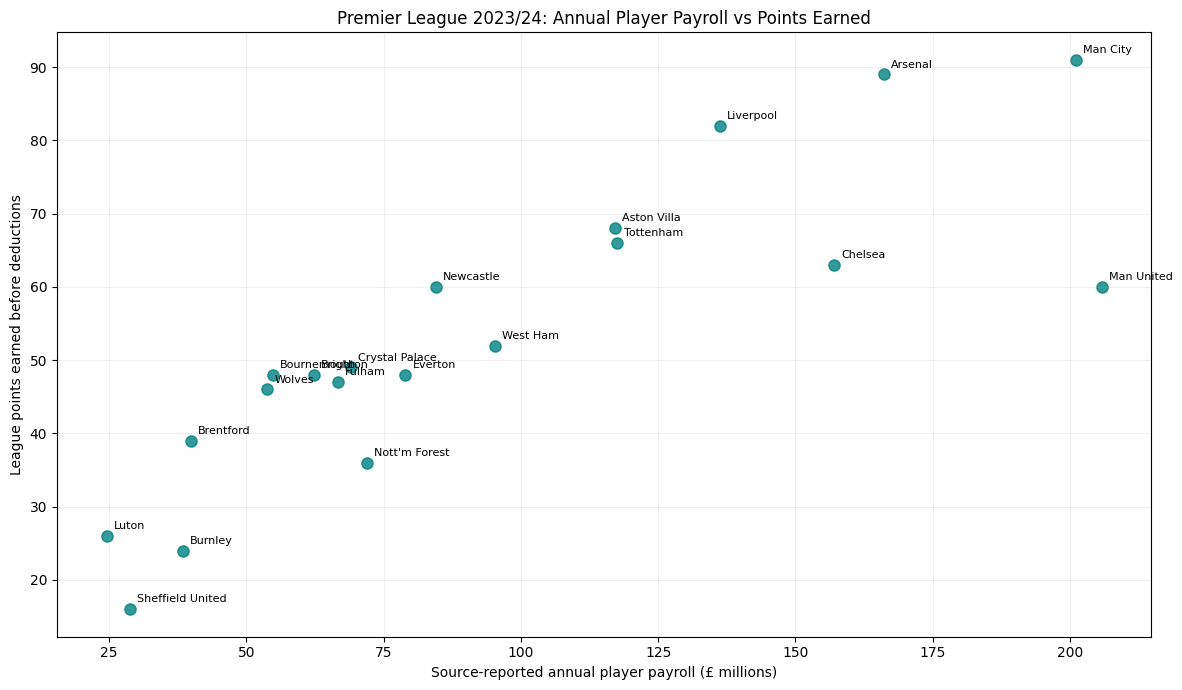

In [13]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 7))

ax.scatter(
    analysis["AnnualPayrollGBP"] / 1_000_000,
    analysis["PointsEarned"],
    color="teal",
    s=65,
    alpha=0.8
)

for _, row in analysis.iterrows():
    ax.annotate(
        row["Team"],
        (
            row["AnnualPayrollGBP"] / 1_000_000,
            row["PointsEarned"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.set_title("Premier League 2023/24: Annual Player Payroll vs Points Earned")
ax.set_xlabel("Source-reported annual player payroll (£ millions)")
ax.set_ylabel("League points earned before deductions")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

imits of these findings
- Payroll figures include estimates; we have not independently verified actual expenditure or fully established the source’s coverage.
- Annual player wages support competitions beyond the Premier League.
- These are descriptive comparisons from one season, not proof of causation.
- Cost per point measures payroll efficiency, not financial profit or a validated prediction.

Club comparisons
- Luton vs Burnley: Luton’s reported payroll was £13.936 million lower, yet it earned 2 more points.
- Brentford vs Burnley: Brentford’s reported payroll was £1.43 million higher, and it earned 15 more points.
- Manchester City vs Manchester United: City’s reported payroll was £4.724 million lower, and it earned 31 more points.

In [14]:
# Measure the linear association across all 20 clubs.
payroll_points_correlation = analysis["AnnualPayrollGBP"].corr(
    analysis["PointsEarned"]
)

print("Number of clubs:", len(analysis))
print(
    "Pearson correlation between payroll and points:",
    round(payroll_points_correlation, 3)
)

Number of clubs: 20
Pearson correlation between payroll and points: 0.847


- Across the 20 EPL clubs in our 2023/24 dataset, reported annual player payroll and league points earned had a Pearson correlation of 0.847.
- This indicates a strong positive linear association: higher-payroll clubs generally earned more points.
- Individual exceptions remain; similar payrolls did not guarantee similar results.
- This is a descriptive result for one season using wage data that includes estimates. It does not establish causation or demonstrate future predictive accuracy.

# We fitted a simple linear payroll–wins benchmark using the 20 clubs in our 2023/24 dataset. Actual wins minus benchmark wins measures performance relative to this fitted relationship. This is a descriptive comparison within the same season, not a tested forecast or proof of management quality. The payroll figures include estimates.

In [15]:
import numpy as np

# Work in a separate table so our existing analysis stays intact.
benchmark = analysis.copy()

# Express payroll in millions of pounds.
payroll_millions = benchmark["AnnualPayrollGBP"] / 1_000_000

# Fit a straight line relating payroll to wins.
slope, intercept = np.polyfit(
    payroll_millions,
    benchmark["Wins"],
    deg=1
)

benchmark["BenchmarkWins"] = (
    intercept + slope * payroll_millions
)

benchmark["WinsAboveBenchmark"] = (
    benchmark["Wins"] - benchmark["BenchmarkWins"]
)

print(
    f"Benchmark wins = {intercept:.2f} "
    f"+ ({slope:.3f} × payroll in £ millions)"
)

display(
    benchmark[
        [
            "Team",
            "AnnualPayrollGBP",
            "Wins",
            "BenchmarkWins",
            "WinsAboveBenchmark"
        ]
    ]
    .sort_values("WinsAboveBenchmark", ascending=False)
    .style.format({
        "AnnualPayrollGBP": "£{:,.0f}",
        "BenchmarkWins": "{:.2f}",
        "WinsAboveBenchmark": "{:+.2f}"
    })
)

Benchmark wins = 4.81 + (0.108 × payroll in £ millions)


,Team,AnnualPayrollGBP,Wins,BenchmarkWins,WinsAboveBenchmark
0,Arsenal,"£166,036,000",28,22.72,+5.28
10,Liverpool,"£136,240,000",24,19.51,+4.49
14,Newcastle,"£84,500,000",18,13.93,+4.07
1,Aston Villa,"£117,150,000",20,17.45,+2.55
17,Tottenham,"£117,520,000",20,17.49,+2.51
19,Wolves,"£53,820,000",13,10.62,+2.38
2,Bournemouth,"£54,834,000",13,10.73,+2.27
12,Man City,"£201,032,000",28,26.50,+1.50
9,Fulham,"£66,690,000",13,12.01,+0.99
3,Brentford,"£39,936,000",10,9.12,+0.88


**How these findings connect**
- The earlier payroll–points correlation of 0.847 shows that higher-payroll clubs generally earned more points across this season.
- The payroll–wins benchmark examines individual clubs’ departures from the fitted payroll relationship.
- These findings can coexist: an overall positive relationship does not mean every higher-payroll club outperforms every lower-payroll club.
- Cost per result measures spending efficiency, while wins above benchmark measures performance relative to a fitted expectation. Their rankings can differ.
- The correlation uses points, while the benchmark uses wins; draws contribute to points but not wins.

**Key findings: Payroll–wins benchmark**
- Arsenal has the largest positive gap in the displayed ranking: +5.28 wins, followed by Liverpool (+4.49) and Newcastle (+4.07).
- Wolves (+2.38) and Bournemouth (+2.27) also exceeded the benchmark with substantially smaller payrolls than those leading clubs.
- Luton had the lowest cost per point in our earlier calculation, but finished 1.46 wins below this benchmark. Those measures answer different questions.
- Manchester United recorded the largest negative gap: 18 actual wins against 27.01 benchmark wins, approximately 9.01 wins below the fitted benchmark. This describes the result; it does not establish why the club underperformed.
- The cheapest cost per win did not produce the largest positive benchmark gap: Brentford had the lowest cost per win, approximately £3.99 million, but exceeded its benchmark by only 0.88 wins. Arsenal’s cost per win was approximately £5.93 million, yet it exceeded its benchmark by 5.28 wins.
- These are comparisons within one season using reported payroll figures, including estimates. We still need to define “lower payroll” before formally identifying our underdogs.

***Identifying lower-payroll clubs that exceeded the benchmark***

In [16]:
# Find the middle payroll across all 20 clubs.
median_payroll = benchmark["AnnualPayrollGBP"].median()

# Apply our definitions without changing the earlier tables.
underdog_analysis = benchmark.copy()

underdog_analysis["LowerPayroll"] = (
    underdog_analysis["AnnualPayrollGBP"] < median_payroll
)

underdog_analysis["AboveBenchmark"] = (
    underdog_analysis["WinsAboveBenchmark"] > 0
)

# Keep ALL lower-payroll clubs, including those below benchmark.
lower_payroll_clubs = underdog_analysis.loc[
    underdog_analysis["LowerPayroll"]
].sort_values("WinsAboveBenchmark", ascending=False)

number_above = int(lower_payroll_clubs["AboveBenchmark"].sum())

print(f"League median annual payroll: £{median_payroll:,.0f}")
print(f"Clubs below the median: {len(lower_payroll_clubs)}")
print(f"Of these, clubs above the wins benchmark: {number_above}")

display(
    lower_payroll_clubs[
        [
            "Team",
            "AnnualPayrollGBP",
            "Wins",
            "BenchmarkWins",
            "WinsAboveBenchmark",
            "AboveBenchmark"
        ]
    ].style.format({
        "AnnualPayrollGBP": "£{:,.0f}",
        "BenchmarkWins": "{:.2f}",
        "WinsAboveBenchmark": "{:+.2f}"
    })
)

League median annual payroll: £75,514,000
Clubs below the median: 10
Of these, clubs above the wins benchmark: 6


,Team,AnnualPayrollGBP,Wins,BenchmarkWins,WinsAboveBenchmark,AboveBenchmark
19,Wolves,"£53,820,000",13,10.62,+2.38,True
2,Bournemouth,"£54,834,000",13,10.73,+2.27,True
9,Fulham,"£66,690,000",13,12.01,+0.99,True
3,Brentford,"£39,936,000",10,9.12,+0.88,True
7,Crystal Palace,"£69,050,000",13,12.26,+0.74,True
4,Brighton,"£62,400,000",12,11.54,+0.46,True
11,Luton,"£24,570,000",6,7.46,-1.46,False
15,Nott'm Forest,"£72,050,000",9,12.59,-3.59,False
5,Burnley,"£38,506,000",5,8.97,-3.97,False
16,Sheffield United,"£28,756,000",3,7.92,-4.92,False


**Key findings: Lower-payroll clubs**
- We defined lower payroll as reported annual payroll below the league median of £75,514,000. Ten clubs met this definition.
- Six of those ten clubs (60%) recorded more wins than the fitted payroll–wins benchmark suggested.
- Wolves ranked first in this group: 13 wins against a benchmark of 10.62, a gap of +2.38 wins.
- Bournemouth ranked second: 13 wins against 10.73, a gap of +2.27 wins.
- Fulham, Brentford, Crystal Palace and Brighton also exceeded the benchmark, each by less than one win.
- Four clubs fell below it: Luton, Nottingham Forest, Burnley and Sheffield United. Sheffield United had the largest negative gap in this group, at −4.92 wins.
- These classifications depend on our chosen payroll threshold and fitted model. Positive gaps are descriptive; they do not establish statistically significant outperformance or future success.

In [17]:
group_comparison = (
    underdog_analysis
    .groupby("LowerPayroll")
    .agg(
        Clubs=("Team", "size"),
        ClubsAboveBenchmark=("AboveBenchmark", "sum"),
        AverageWinsAboveBenchmark=("WinsAboveBenchmark", "mean")
    )
    .rename(index={
        True: "Below median payroll",
        False: "At or above median payroll"
    })
)

group_comparison["PercentAboveBenchmark"] = (
    group_comparison["ClubsAboveBenchmark"]
    / group_comparison["Clubs"] * 100
)

display(
    group_comparison.style.format({
        "AverageWinsAboveBenchmark": "{:+.2f}",
        "PercentAboveBenchmark": "{:.0f}%"
    })
)

,Clubs,ClubsAboveBenchmark,AverageWinsAboveBenchmark,PercentAboveBenchmark
LowerPayroll,,,,
At or above median payroll,10,6,+0.62,60%
Below median payroll,10,6,-0.62,60%



- Both payroll groups had six of ten clubs (60%) above the fitted wins benchmark.
- Lower-payroll clubs averaged 0.62 wins below benchmark, while the other group averaged 0.62 wins above benchmark.
- Within the lower-payroll group, the combined shortfalls outweighed the positive gaps despite a majority exceeding the benchmark.
- This season shows individual lower-payroll outperformers, but these measures do not show a general advantage for the lower-payroll group.
- These are descriptive results from one season and one fitted model, not evidence that changing payroll causes a change in performance.

In [18]:
threshold_checks = []

for definition, cutoff in {
    "Below median payroll": benchmark["AnnualPayrollGBP"].median(),
    "Below mean payroll": benchmark["AnnualPayrollGBP"].mean()
}.items():

    group = benchmark.loc[
        benchmark["AnnualPayrollGBP"] < cutoff
    ]

    above = group["WinsAboveBenchmark"] > 0

    threshold_checks.append({
        "Definition": definition,
        "PayrollCutoffGBP": cutoff,
        "Clubs": len(group),
        "ClubsAboveBenchmark": int(above.sum()),
        "PercentAboveBenchmark": above.mean() * 100,
        "AverageWinsAboveBenchmark":
            group["WinsAboveBenchmark"].mean()
    })

sensitivity = pd.DataFrame(threshold_checks)

display(
    sensitivity.style.format({
        "PayrollCutoffGBP": "£{:,.0f}",
        "PercentAboveBenchmark": "{:.1f}%",
        "AverageWinsAboveBenchmark": "{:+.2f}"
    })
)

,Definition,PayrollCutoffGBP,Clubs,ClubsAboveBenchmark,PercentAboveBenchmark,AverageWinsAboveBenchmark
0,Below median payroll,"£75,514,000",10,6,60.0%,-0.62
1,Below mean payroll,"£93,509,000",12,7,58.3%,-0.21



- Raising the lower-payroll cutoff from the median to the mean expanded the group from 10 to 12 clubs, adding Everton and Newcastle.
- The share above benchmark changed from 60% to 58.3%.
- The average gap improved from −0.62 to −0.21 wins, remaining negative under both definitions.
- The conclusion that this group did not exceed the benchmark on average holds under these two cutoffs. This is a limited sensitivity check, not proof that the conclusion holds under every model or definition.
- We retain the median as our primary definition.

In [19]:
# Measure how far actual wins sit from the fitted benchmark.
absolute_gaps = benchmark["WinsAboveBenchmark"].abs()

benchmark_mae = absolute_gaps.mean()

print(f"Clubs assessed: {len(benchmark)}")
print(
    "Average absolute gap from the fitted benchmark: "
    f"{benchmark_mae:.2f} wins"
)

Clubs assessed: 20
Average absolute gap from the fitted benchmark: 2.81 wins



- The payroll–wins benchmark had an in-sample mean absolute error of 2.81 wins across 20 clubs.
- This measures the average distance between actual wins and fitted benchmark wins, regardless of direction.
- Small positive gaps should be described cautiously; being above benchmark alone does not prove exceptional performance.
- This is a measure of fit on the data used to build the benchmark, not independently tested prediction accuracy.

In [20]:
# Simple baseline: give every club the league-average win total.
average_wins = benchmark["Wins"].mean()

baseline_mae = (
    benchmark["Wins"] - average_wins
).abs().mean()

payroll_mae = (
    benchmark["Wins"] - benchmark["BenchmarkWins"]
).abs().mean()

fit_comparison = pd.DataFrame({
    "Benchmark": [
        "Same average wins for every club",
        "Payroll-based fitted wins"
    ],
    "InSampleMAE": [baseline_mae, payroll_mae]
})

print(f"League-average wins per club: {average_wins:.2f}")

display(
    fit_comparison.style.format({
        "InSampleMAE": "{:.2f}"
    })
)

League-average wins per club: 14.90


,Benchmark,InSampleMAE
0,Same average wins for every club,5.48
1,Payroll-based fitted wins,2.81



- The payroll benchmark fitted the observed win totals more closely than assigning every club the league average of 14.9 wins.
- In-sample MAE fell from 5.48 to 2.81 wins, a reduction of approximately 49%.
- This supports using payroll as a descriptive benchmark for this dataset, but does not establish performance on future seasons.

In [21]:
dashboard_data = underdog_analysis[
    [
        "Team",
        "AnnualPayrollGBP",
        "Wins",
        "Draws",
        "Losses",
        "Played",
        "PointsEarned",
        "CostPerWinGBP",
        "CostPerPointGBP",
        "BenchmarkWins",
        "WinsAboveBenchmark",
        "LowerPayroll",
        "AboveBenchmark",
        "% Estimated"
    ]
].copy()

dashboard_data = dashboard_data.rename(
    columns={"% Estimated": "EstimatedContractsPct"}
)

# Store percentages as numbers on a 0–100 scale.
dashboard_data["EstimatedContractsPct"] = pd.to_numeric(
    dashboard_data["EstimatedContractsPct"]
    .astype(str)
    .str.replace("%", "", regex=False)
    .str.strip(),
    errors="raise"
)

dashboard_data.insert(0, "Season", "2023/24")

# Check the table before exporting.
assert len(dashboard_data) == 20
assert dashboard_data["Team"].is_unique
assert dashboard_data.notna().all().all()
assert dashboard_data["Played"].eq(38).all()
assert dashboard_data["AnnualPayrollGBP"].gt(0).all()
assert dashboard_data["EstimatedContractsPct"].between(0, 100).all()

print("Checks passed: 20 unique clubs, no missing values.")
display(dashboard_data.head())

Checks passed: 20 unique clubs, no missing values.


,Season,Team,AnnualPayrollGBP,Wins,Draws,Losses,Played,PointsEarned,CostPerWinGBP,CostPerPointGBP,BenchmarkWins,WinsAboveBenchmark,LowerPayroll,AboveBenchmark,EstimatedContractsPct
0,2023/24,Arsenal,166036000,28,5,5,38,89,5.929857e+06,1.865573e+06,22.722387,5.277613,False,True,12
1,2023/24,Aston Villa,117150000,20,8,10,38,68,5.857500e+06,1.722794e+06,17.449796,2.550204,False,True,48
2,2023/24,Bournemouth,54834000,13,9,16,38,48,4.218000e+06,1.142375e+06,10.728715,2.271285,True,True,79
3,2023/24,Brentford,39936000,10,9,19,38,39,3.993600e+06,1.024000e+06,9.121893,0.878107,True,True,93
4,2023/24,Brighton,62400000,12,12,14,38,48,5.200000e+06,1.300000e+06,11.544744,0.455256,True,True,77


In [22]:
from google.colab import files

export_filename = "epl_payroll_efficiency_2023_24.csv"

dashboard_data.to_csv(
    export_filename,
    index=False,
    encoding="utf-8-sig"
)

print(f"Exported {len(dashboard_data)} clubs.")
files.download(export_filename)

Exported 20 clubs.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

This project examined whether lower-payroll Premier League clubs outperformed their budgets in 2023/24. It combined 380 match results with reported annual squad payroll figures for 20 clubs.

Lower payroll was defined as below the league median of £75.514 million. Six of the ten clubs in this group exceeded a fitted payroll–wins benchmark. Wolves (+2.38 wins) and Bournemouth (+2.27) recorded the largest positive gaps within that group.

However, both payroll groups had the same above-benchmark rate of 60%. The lower-payroll group also averaged 0.62 wins below benchmark. These results identify individual outperformers without demonstrating a general advantage for lower-payroll clubs.

Brentford recorded the lowest payroll per league win (£3.99 million). Manchester United recorded the highest (£11.43 million) and the largest negative benchmark gap (−9.01 wins). Cost per win and wins above benchmark therefore provide different perspectives on performance.

The analysis is descriptive: it covers one season, uses payroll figures that include estimates, and evaluates the benchmark on the same clubs used to fit it. It does not establish causes or demonstrate future predictive accuracy.